# 02 - Feature engineering, model training & experiment tracking
Training is implemented in `src/heart_risk/train.py` (also run by CI). This notebook re-runs it on demand and analyses the MLflow experiment.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 140)

## 1. Preprocessing pipeline
Engineered features -> impute -> scale numerics / one-hot categoricals. Everything is one sklearn `Pipeline`, so the saved artefact accepts raw patient records.

In [2]:
from heart_risk.features import build_preprocessor
from heart_risk.data import load_clean, split_xy
X, y = split_xy(load_clean())
pre = build_preprocessor().fit(X)
names = pre.named_steps['columns'].get_feature_names_out()
print(len(names), 'model features:')
print(list(names))

26 model features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'hr_pct_of_max', 'rate_pressure_product', 'st_risk', 'vessel_age_burden', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0', 'sex', 'fbs', 'exang']


## 2. Train (set `RETRAIN = True` to create new MLflow runs)

In [3]:
RETRAIN = False
from heart_risk import config
if RETRAIN or not config.MODEL_FILE.exists():
    from heart_risk.train import run
    run()

## 3. Experiment summary from MLflow

In [4]:
import mlflow
mlflow.set_tracking_uri((ROOT / 'mlruns').as_uri())
runs = mlflow.search_runs(experiment_names=[config.EXPERIMENT_NAME])
parents = runs[runs['tags.mlflow.parentRunId'].isna()]
cols = ['tags.mlflow.runName','metrics.cv_roc_auc_mean','metrics.cv_roc_auc_std','metrics.cv_f1_mean','metrics.test_accuracy','metrics.test_precision','metrics.test_recall','metrics.test_roc_auc','metrics.decision_threshold','metrics.test_tuned_recall','tags.champion']
parents = parents.assign(stability=parents['metrics.cv_roc_auc_mean'] - parents['metrics.cv_roc_auc_std'])
parents[cols + ['stability']].sort_values('stability', ascending=False).round(4)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,metrics.cv_f1_mean,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc,metrics.decision_threshold,metrics.test_tuned_recall,tags.champion,stability
84,logistic_regression,0.9076,0.0168,0.8288,0.8689,0.8125,0.9286,0.9610,0.302,0.9643,true,0.8907
18,extra_trees,0.9058,0.0215,0.7976,0.8689,0.8125,0.9286,0.9437,NaN,NaN,None,0.8843
55,random_forest,0.8989,0.0186,0.7904,0.8525,0.7879,0.9286,0.9610,NaN,NaN,None,0.8803


In [5]:
children = runs[runs['tags.mlflow.parentRunId'].notna()]
print('nested hyper-parameter runs logged:', len(children))
children.groupby(children['tags.mlflow.runName'].str.rsplit('-', n=1).str[0])['metrics.cv_roc_auc_mean'].describe().round(4)

nested hyper-parameter runs logged: 82


,count,mean,std,min,25%,50%,75%,max
tags.mlflow.runName,,,,,,,,
extra_trees,18.0,0.8972,0.0066,0.8842,0.8926,0.8970,0.9036,0.9058
logistic_regression,28.0,0.8989,0.0075,0.8760,0.8965,0.8985,0.9046,0.9076
random_forest,36.0,0.8934,0.0042,0.8803,0.8911,0.8949,0.8956,0.8989


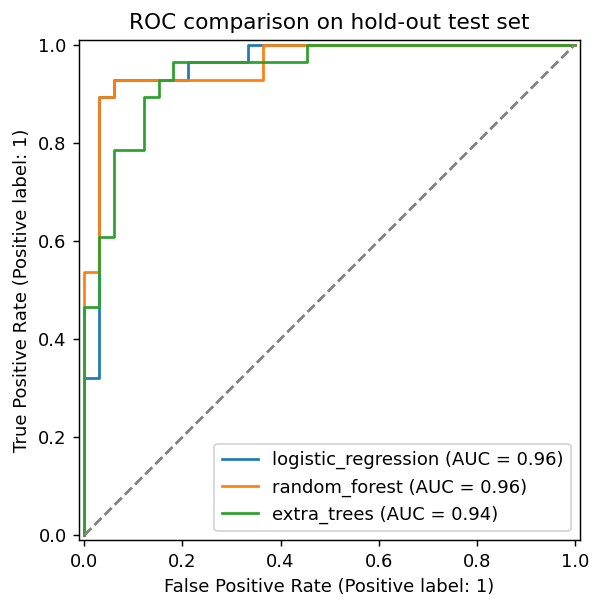

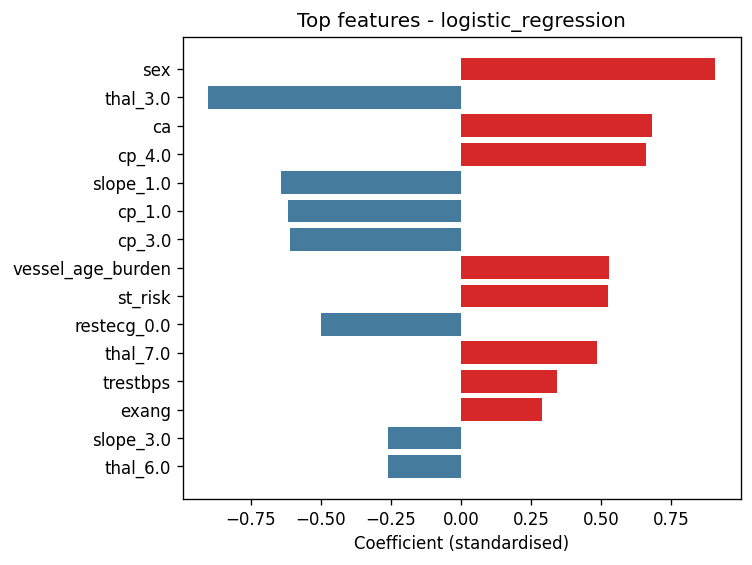

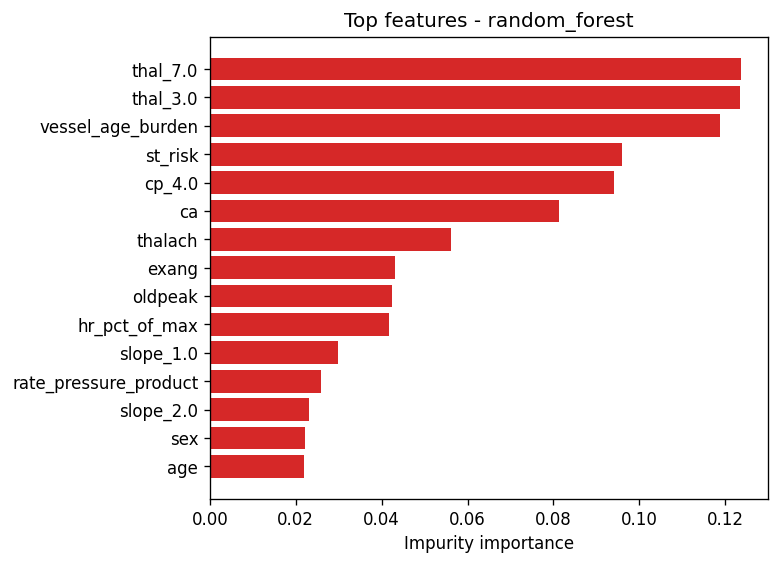

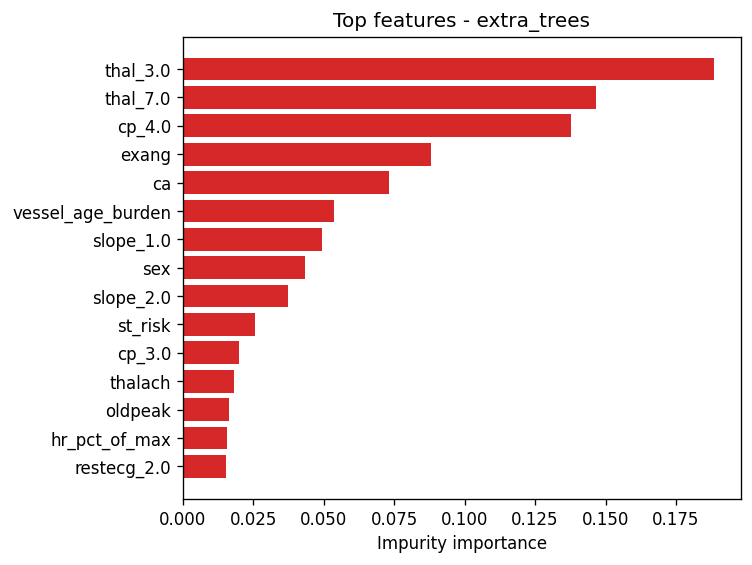

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'reports/training/roc_comparison.png')))
for m in ['logistic_regression','random_forest','extra_trees']:
    display(Image(filename=str(
        ROOT/f'reports/training/feature_importance_{m}.png')))

## 4. Model selection and threshold
The champion maximises **mean CV ROC-AUC minus its standard deviation** across the 5 folds (a stability-penalised score), computed on the training split only; the 61-row test split is never used for choosing. Logistic regression wins this rule and is also the most interpretable model, which matters for a clinical risk score.

Because missing a sick patient is costlier than a false alarm, the decision threshold is then tuned on **out-of-fold** predictions to the highest value that still gives >= 90% recall. The tuned threshold and its test metrics are logged to MLflow (`decision_threshold`, `test_tuned_*`) and stored in `models/metadata.json`, where the API picks them up.